In [81]:
%pip install pandas
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [82]:
import pandas as pd 

pd.set_option("display.float_format", "{:,.2f}".format)
df = pd.read_csv("TXRPI.csv")

df.head()
df.tail()

,observation_date,TXRPI
12,2020-01-01,"1,555,001.10"
13,2021-01-01,"1,668,999.20"
14,2022-01-01,"1,699,958.50"
15,2023-01-01,"1,773,259.80"
16,2024-01-01,"1,821,733.60"


Missing values
Date                          0
Texas_Real_Personal_Income    0
Growth Rate                   1
Category                      0
dtype: int64
Missing Percentage
Date                         0.00
Texas_Real_Personal_Income   0.00
Growth Rate                  5.88
Category                     0.00
dtype: float64


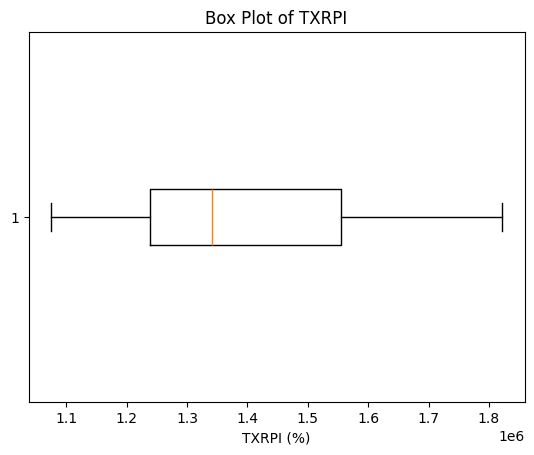

In [94]:
missing_counts=df.isnull().sum()
missing_percentage=(missing_counts/len(df)*100)
print("Missing values")
print(missing_counts)
print("Missing Percentage")
print(missing_percentage)

import matplotlib.pyplot as plt
plt.boxplot(df["Texas_Real_Personal_Income"], vert=False)
plt.xlabel("TXRPI (%)")
plt.title("Box Plot of TXRPI")
plt.show()

In [84]:
duplicate_count=df.duplicated().sum()
print(f"number of duplicate rows: {duplicate_count}")
df = df.rename(columns = {"TXRPI": "Texas_Real_Personal_Income", "observation_date": "Date"})
df.head()
print ("value Counts for Income:")
print(df["Texas_Real_Personal_Income"].value_counts())

number of duplicate rows: 0
value Counts for Income:
Texas_Real_Personal_Income
1,119,862.80    1
1,407,127.70    1
1,773,259.80    1
1,699,958.50    1
1,668,999.20    1
1,555,001.10    1
1,510,420.10    1
1,469,625.40    1
1,326,896.00    1
1,075,132.00    1
1,341,875.70    1
1,317,164.60    1
1,250,339.10    1
1,238,906.90    1
1,195,876.20    1
1,112,452.40    1
1,821,733.60    1
Name: count, dtype: int64


In [85]:
df.to_csv("data/cleaned/TXRPI_cleaned.csv", index=False)

In [86]:
print("basics statistics for Texas Real Personal Income")

print(df["Texas_Real_Personal_Income"].describe())
#use .var() as a shortcut to get Count, Mean, Standard Deviation, Minimum, Maximum, and Quartiles
variance = df["Texas_Real_Personal_Income"].var()
print("Variance:", variance)

Q1=df["Texas_Real_Personal_Income"].quantile(.25)
Q3=df["Texas_Real_Personal_Income"].quantile(.75)
IQR=Q3-Q1
print(f"IQR: {IQR}")

basics statistics for Texas Real Personal Income
count          17.00
mean    1,404,978.30
std       236,182.24
min     1,075,132.00
25%     1,238,906.90
50%     1,341,875.70
75%     1,555,001.10
max     1,821,733.60
Name: Texas_Real_Personal_Income, dtype: float64
Variance: 55782051284.78377
IQR: 316094.2000000002


In [87]:
#Calculating the growth rate of Texas Real Personal Income
df["Growth Rate"] = df["Texas_Real_Personal_Income"].pct_change() * 100
#Rules for categorizing for plotting the growth rate
def categorizing_growth(rate):
    if pd.isna(rate):
        return "No Data"
    elif rate > 0:
        return "Rising Growth"
    elif rate < 0:
        return "Falling Growth"

#Creating a new coloumn named Category and filled it using the Growth Rate coloumn and the categorizing_growth function
df["Category"] = df["Growth Rate"].apply(categorizing_growth)




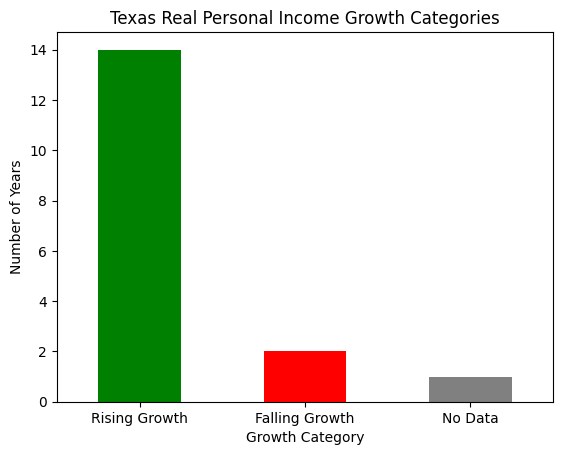

In [88]:
import matplotlib.pyplot as plt
# Counts how many years fall into each category
category_counts = df["Category"].value_counts()

category_counts.plot(kind="bar", color=["green", "red", "gray"])

plt.title("Texas Real Personal Income Growth Categories")
plt.xlabel("Growth Category")
plt.ylabel("Number of Years")
plt.xticks(rotation=0)
plt.show()

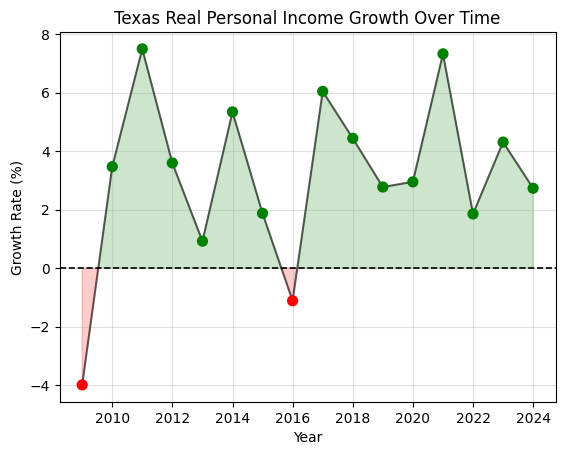

In [89]:
#Allows matplotlib to graph it chronologically
df["Date"] = pd.to_datetime(df["Date"])

# Original code for plotting the growth rate over time

# plt.plot(df["Date"], df["Growth Rate"], marker="o", linestyle="-", color="blue")
# plt.title("Texas Real Personal Income Over Time")
# plt.xlabel("Year")
# plt.ylabel("Growth Rate (%)")
# plt.grid(True)
# plt.show()

#Asked AI to make it so when the growth rate is positive it is green and when it is negative it is red
df["Date"] = pd.to_datetime(df["Date"])

# 1. Plot the main connecting line in a neutral dark color
plt.plot(df["Date"], df["Growth Rate"], linestyle="-", color="black", alpha=0.6)

# 2. Add a bold dashed reference line right at 0%
plt.axhline(0, color="black", linestyle="--", linewidth=1.2)

# 3. Color the dots: Green if >= 0, Red if < 0
colors = ["green" if rate >= 0 else "red" for rate in df["Growth Rate"]]
plt.scatter(df["Date"], df["Growth Rate"], color=colors, s=50, zorder=5)

# 4. Shade the area above 0 green and below 0 red
plt.fill_between(df["Date"], df["Growth Rate"], 0, 
                 where=(df["Growth Rate"] >= 0), color="green", alpha=0.2, interpolate=True)
plt.fill_between(df["Date"], df["Growth Rate"], 0, 
                 where=(df["Growth Rate"] < 0), color="red", alpha=0.2, interpolate=True)

# 5. Updated Version with AI Touch
plt.title("Texas Real Personal Income Growth Over Time")
plt.xlabel("Year")
plt.ylabel("Growth Rate (%)")
plt.grid(True, alpha=0.4)
plt.show()
